In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
df = pd.read_csv("client_data.csv")

features = [
    "inquiry_source_score",
    "mentioned_business_income",
    "response_time_hours",
    "requested_pricing_info",
    "lead_hot",
    "years_as_client",
    "filing_complexity_score",
    "addons_purchased",
    "referrals_given",
    "num_income_sources",
    "past_filing_errors",
    "time_spent_selfiling_minutes",
    "deductions_claimed_count",
    "dependents_count",
    "support_contacts_count",
    "staff_hours_spent",
    "forms_filed_count",
    "revisions_count",
    "current_fee_charged"
]

target_column = "premium_upgrade"

data = df[features + [target_column]].copy()

data = data.dropna()

X = data[features].values
y = data[target_column].values.astype(int)

In [2]:
from sklearn.model_selection import train_test_split
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y
)
X_validation, X_test, y_validation, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)
print("Training:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

Training: (1500, 19)
Validation: (500, 19)
Test: (500, 19)


In [3]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_validation_scaled = scaler.transform(X_validation)
X_test_scaled = scaler.transform(X_test)

In [39]:
import numpy as np
print("NaN:", np.isnan(X_train_scaled).sum())
print("Infinity:", np.isinf(X_train_scaled).sum())

NaN: 0
Infinity: 0


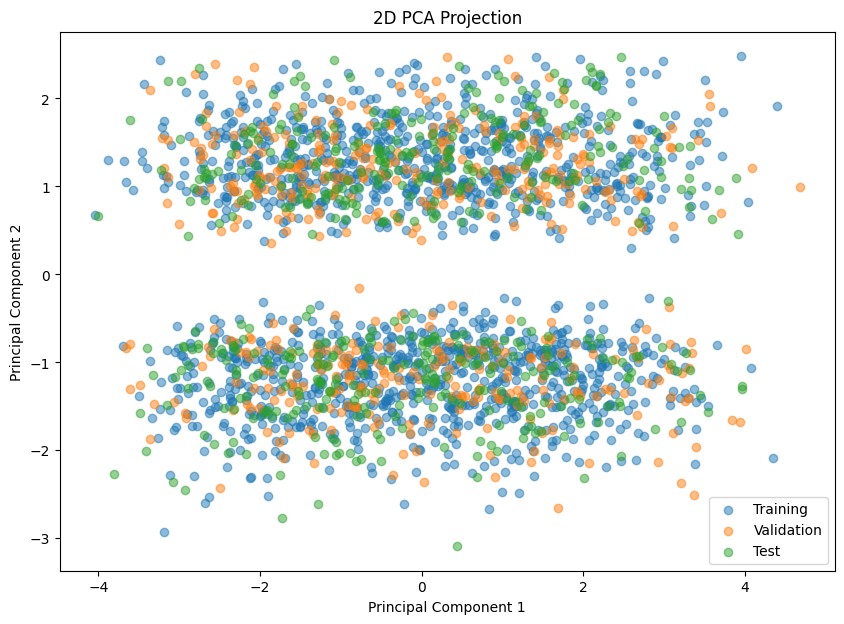

In [41]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
pca = PCA(n_components=2)
X_train_2d = pca.fit_transform(X_train_scaled)
X_validation_2d = pca.transform(X_validation_scaled)
X_test_2d = pca.transform(X_test_scaled)
plt.figure(figsize=(10, 7))
plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], label="Training", alpha=0.5)
plt.scatter(X_validation_2d[:, 0], X_validation_2d[:, 1], label="Validation", alpha=0.5)
plt.scatter(X_test_2d[:, 0], X_test_2d[:, 1], label="Test", alpha=0.5)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D PCA Projection")
plt.legend()
plt.show()

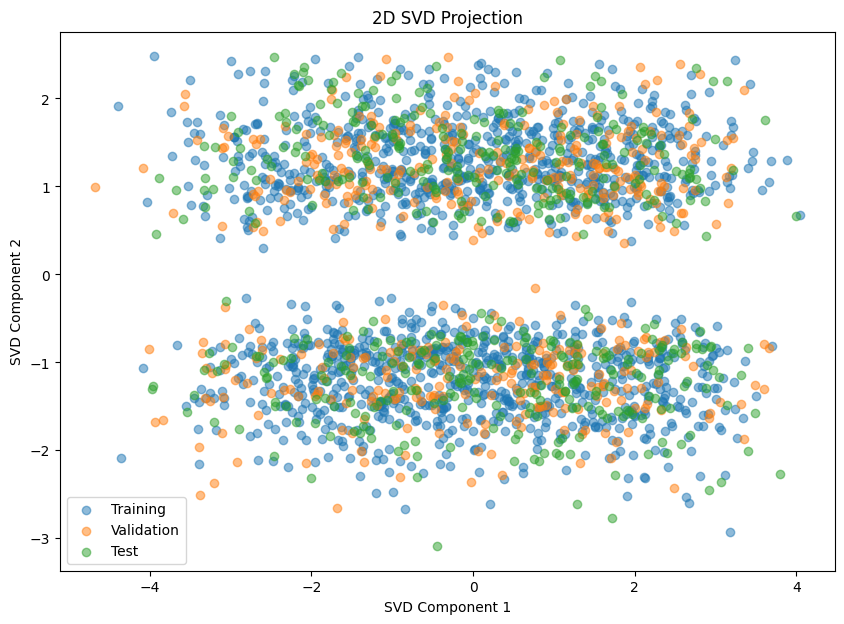

In [42]:
import numpy as np
import matplotlib.pyplot as plt

U_train, S_train, Vt_train = np.linalg.svd(X_train_scaled, full_matrices=False)

X_train_2d = U_train[:, :2] @ np.diag(S_train[:2])

X_validation_2d = X_validation_scaled @ Vt_train[:2].T
X_test_2d = X_test_scaled @ Vt_train[:2].T

plt.figure(figsize=(10, 7))

plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], label="Training", alpha=0.5)
plt.scatter(X_validation_2d[:, 0], X_validation_2d[:, 1], label="Validation", alpha=0.5)
plt.scatter(X_test_2d[:, 0], X_test_2d[:, 1], label="Test", alpha=0.5)

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("2D SVD Projection")
plt.legend()
plt.show()

In [4]:
def perceptron_train(
    X,
    y,
    learning_rate=0.01,
    epochs=50
):
    weights = np.zeros(X.shape[1])
    bias = 0
    misclassifications = []
    for epoch in range(epochs):
        errors = 0
        for i in range(len(X)):
            linear_output = np.dot(X[i], weights) + bias
            prediction = 1 if linear_output >= 0 else 0
            update = learning_rate * (y[i] - prediction)
            weights = weights + update * X[i]
            bias = bias + update
            if update != 0:
                errors += 1
        misclassifications.append(errors)
    return weights, bias, misclassifications

In [5]:
start_time = time.time()
perceptron_weights, perceptron_bias, misclassifications = perceptron_train(
    X_train_scaled,
    y_train,
    learning_rate=0.01,
    epochs=50
)
perceptron_training_time = time.time() - start_time
print("Training Time:", perceptron_training_time)

Training Time: 0.49724793434143066


In [6]:
def perceptron_predict(X, weights, bias):
    scores = np.dot(X, weights) + bias
    predictions = (scores >= 0).astype(int)
    return predictions

In [7]:
perceptron_train_predictions = perceptron_predict(
    X_train_scaled,
    perceptron_weights,
    perceptron_bias
)
perceptron_validation_predictions = perceptron_predict(
    X_validation_scaled,
    perceptron_weights,
    perceptron_bias
)
perceptron_test_predictions = perceptron_predict(
    X_test_scaled,
    perceptron_weights,
    perceptron_bias
)

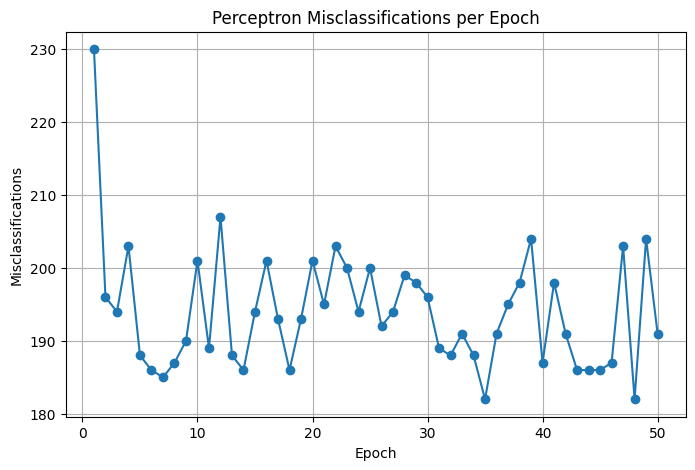

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(misclassifications) + 1),
    misclassifications,
    marker="o"
)
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.title("Perceptron Misclassifications per Epoch")
plt.grid()
plt.show()

In [ ]:
plot_features = [
    "filing_complexity_score",
    "support_contacts_count"
]
X_2d = data[plot_features].values
y_2d = data[target_column].values.astype(int)
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

In [10]:
weights_2d, bias_2d, errors_2d = perceptron_train(
    X_2d_scaled,
    y_2d,
    learning_rate=0.01,
    epochs=30
)

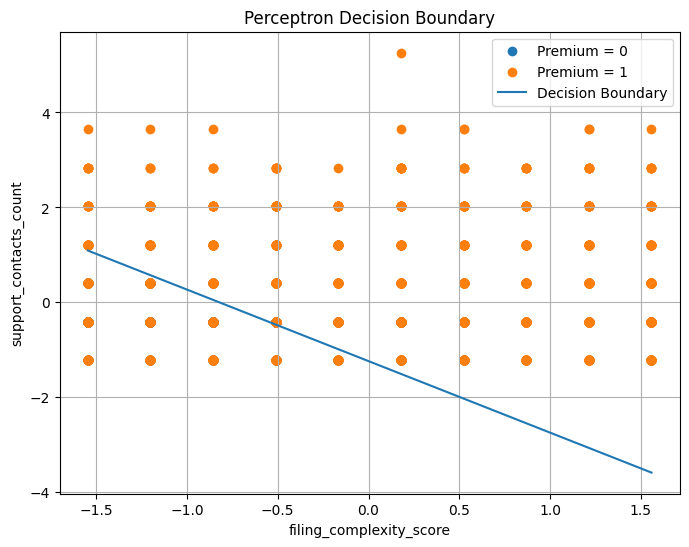

In [11]:
plt.figure(figsize=(8, 6))
for class_value in [0, 1]:
    mask = y_2d == class_value
    plt.scatter(
        X_2d_scaled[mask, 0],
        X_2d_scaled[mask, 1],
        label=f"Premium = {class_value}"
    )
x_values = np.linspace(
    X_2d_scaled[:, 0].min(),
    X_2d_scaled[:, 0].max(),
    100
)
if weights_2d[1] != 0:
    y_values = (
        -(weights_2d[0] * x_values + bias_2d)
        / weights_2d[1]
    )
    plt.plot(
        x_values,
        y_values,
        label="Decision Boundary"
    )
plt.xlabel(plot_features[0])
plt.ylabel(plot_features[1])
plt.title("Perceptron Decision Boundary")
plt.legend()
plt.grid()
plt.show()

In [12]:
def sigmoid(z):  
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [13]:
def logistic_regression_train(
    X,
    y,
    learning_rate=0.01,
    iterations=5000
):
    m, n = X.shape
    weights = np.zeros(n)
    bias = 0
    cost_history = []
    for i in range(iterations):
        linear_output = np.dot(X, weights) + bias
        probabilities = sigmoid(linear_output)
        errors = probabilities - y
        weight_gradient = (1 / m) * np.dot(
            X.T,
            errors
        )
        bias_gradient = (1 / m) * np.sum(errors)
        weights = weights - learning_rate * weight_gradient
        bias = bias - learning_rate * bias_gradient
        cost = -(
            1 / m
        ) * np.sum(
            y * np.log(probabilities + 1e-15)
            +
            (1 - y) * np.log(1 - probabilities + 1e-15)
        )
        cost_history.append(cost)
    return weights, bias, cost_history

In [14]:
start_time = time.time()
logistic_weights, logistic_bias, logistic_cost_history = (
    logistic_regression_train(
        X_train_scaled,
        y_train,
        learning_rate=0.01,
        iterations=5000
    )
)
logistic_training_time = time.time() - start_time
print("Training Time:", logistic_training_time)

Training Time: 0.7623038291931152


In [15]:
def logistic_predict_probability(
    X,
    weights,
    bias
):
    scores = np.dot(X, weights) + bias
    return sigmoid(scores)

In [16]:
logistic_train_probabilities = logistic_predict_probability(
    X_train_scaled,
    logistic_weights,
    logistic_bias
)
logistic_validation_probabilities = logistic_predict_probability(
    X_validation_scaled,
    logistic_weights,
    logistic_bias
)
logistic_test_probabilities = logistic_predict_probability(
    X_test_scaled,
    logistic_weights,
    logistic_bias
)

In [17]:
def logistic_predict(
    probabilities,
    threshold=0.5
):
    return (probabilities >= threshold).astype(int)

In [18]:
logistic_test_predictions = logistic_predict(
    logistic_test_probabilities,
    threshold=0.5
)

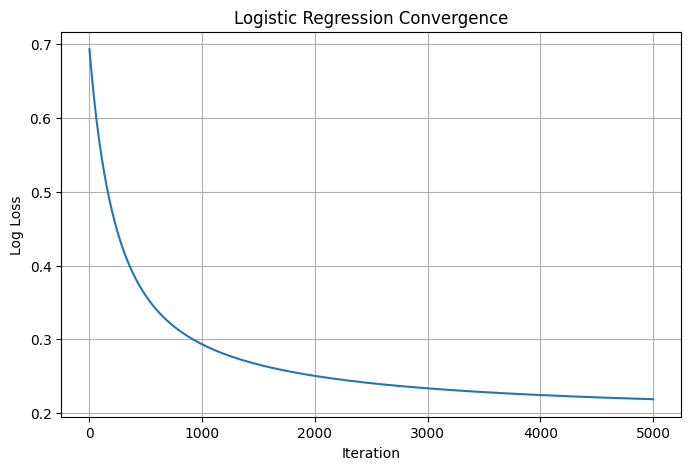

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(
    logistic_cost_history
)
plt.xlabel("Iteration")
plt.ylabel("Log Loss")
plt.title("Logistic Regression Convergence")
plt.grid()
plt.show()

In [20]:
from sklearn.metrics import accuracy_score
perceptron_accuracy = accuracy_score(
    y_test,
    perceptron_test_predictions
)
logistic_accuracy = accuracy_score(
    y_test,
    logistic_test_predictions
)
print("Perceptron Accuracy:", perceptron_accuracy)
print("Logistic Regression Accuracy:", logistic_accuracy)
print("\nPerceptron Training Time:", perceptron_training_time)
print("Logistic Training Time:", logistic_training_time)

Perceptron Accuracy: 0.846
Logistic Regression Accuracy: 0.882

Perceptron Training Time: 0.49724793434143066
Logistic Training Time: 0.7623038291931152


In [21]:
def confusion_matrix_manual(
    y_true,
    y_pred
):
    tp = np.sum(
        (y_true == 1) & (y_pred == 1)
    )
    tn = np.sum(
        (y_true == 0) & (y_pred == 0)
    )
    fp = np.sum(
        (y_true == 0) & (y_pred == 1)
    )
    fn = np.sum(
        (y_true == 1) & (y_pred == 0)
    )
    return tn, fp, fn, tp

In [22]:
def confusion_matrix_manual(
    y_true,
    y_pred
):
    tp = np.sum(
        (y_true == 1) & (y_pred == 1)
    )
    tn = np.sum(
        (y_true == 0) & (y_pred == 0)
    )
    fp = np.sum(
        (y_true == 0) & (y_pred == 1)
    )
    fn = np.sum(
        (y_true == 1) & (y_pred == 0)
    )
    return tn, fp, fn, tp

In [24]:
tn, fp, fn, tp = confusion_matrix_manual(
    y_test,
    logistic_test_predictions
)
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

TN: 29
FP: 39
FN: 20
TP: 412


In [25]:
accuracy = (tp + tn) / (tp + tn + fp + fn)

In [26]:
precision = tp / (tp + fp + 1e-15)

In [27]:
recall = tp / (tp + fn + 1e-15)

In [28]:
f1 = (
    2 * precision * recall
    / (precision + recall + 1e-15)
)

In [29]:
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

Accuracy : 0.882
Precision: 0.9135254988913526
Recall   : 0.9537037037037037
F1-score : 0.9331823329558319


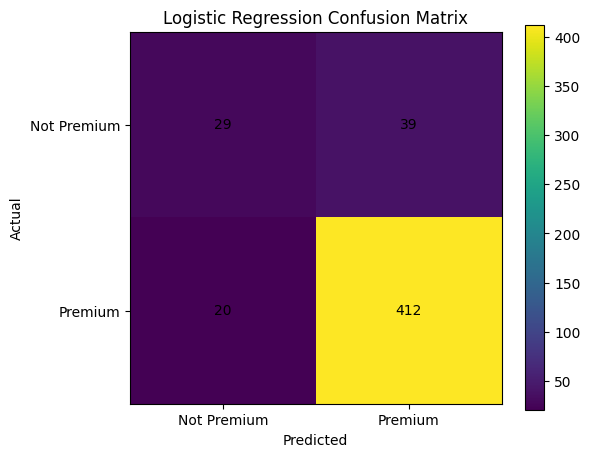

In [30]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
plt.figure(figsize=(6, 5))
plt.imshow(confusion_matrix)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["Not Premium", "Premium"])
plt.yticks([0, 1], ["Not Premium", "Premium"])
for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            confusion_matrix[i, j],
            ha="center",
            va="center"
        )
plt.colorbar()
plt.show()

ROC-AUC Score: 0.9038671023965141


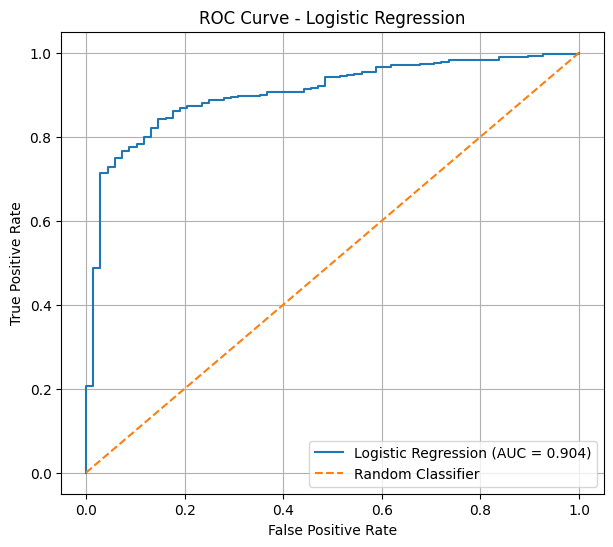

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, thresholds = roc_curve(
    y_test,
    logistic_test_probabilities
)
auc_score = roc_auc_score(
    y_test,
    logistic_test_probabilities
)
print("ROC-AUC Score:", auc_score)
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")

plt.legend()
plt.grid()

plt.show()

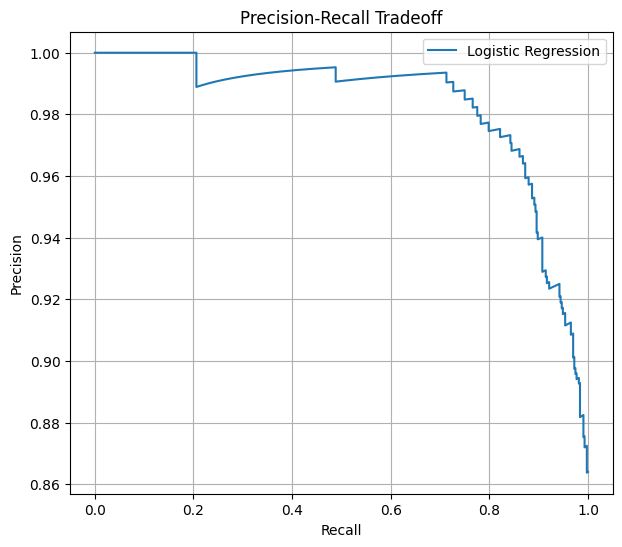

In [34]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test,
    logistic_test_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    label="Logistic Regression"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Tradeoff")

plt.legend()
plt.grid()

plt.show()

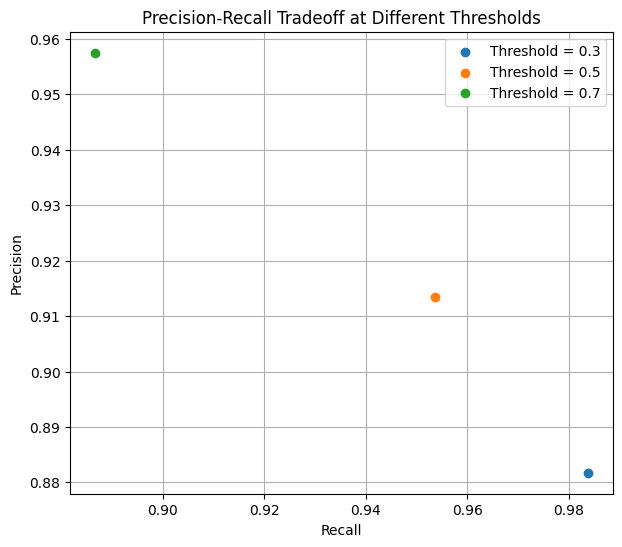

In [35]:
threshold_values = [0.3, 0.5, 0.7]

plt.figure(figsize=(7, 6))

for threshold in threshold_values:

    predictions = logistic_predict(
        logistic_test_probabilities,
        threshold=threshold
    )

    precision_value = np.sum(
        (predictions == 1) & (y_test == 1)
    ) / max(np.sum(predictions == 1), 1)

    recall_value = np.sum(
        (predictions == 1) & (y_test == 1)
    ) / max(np.sum(y_test == 1), 1)

    plt.scatter(
        recall_value,
        precision_value,
        label=f"Threshold = {threshold}"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Tradeoff at Different Thresholds")
plt.legend()
plt.grid()

plt.show()

In [36]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
thresholds = [0.3, 0.5, 0.7]

results = []

for threshold in thresholds:

    predictions = logistic_predict(
        logistic_validation_probabilities,
        threshold=threshold
    )

    accuracy = accuracy_score(y_validation, predictions)
    precision = precision_score(y_validation, predictions)
    recall = recall_score(y_validation, predictions)
    f1 = f1_score(y_validation, predictions)

    results.append({
        "threshold": threshold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })

# Select threshold with highest F1 score
best_result = max(
    results,
    key=lambda x: x["f1_score"]
)

optimal_threshold = best_result["threshold"]

print("\nThreshold Analysis")

for result in results:
    print(
        f"Threshold: {result['threshold']} "
        f"| Accuracy: {result['accuracy']:.4f} "
        f"| Precision: {result['precision']:.4f} "
        f"| Recall: {result['recall']:.4f} "
        f"| F1: {result['f1_score']:.4f}"
    )

print("\nOptimal Threshold:", optimal_threshold)
print("Best F1 Score:", best_result["f1_score"])


Threshold Analysis
Threshold: 0.3 | Accuracy: 0.8840 | Precision: 0.8880 | Recall: 0.9907 | F1: 0.9365
Threshold: 0.5 | Accuracy: 0.8900 | Precision: 0.9274 | Recall: 0.9468 | F1: 0.9370
Threshold: 0.7 | Accuracy: 0.8580 | Precision: 0.9664 | Recall: 0.8657 | F1: 0.9133

Optimal Threshold: 0.5
Best F1 Score: 0.9369988545246277
